<a href="https://colab.research.google.com/github/pjacierda/busa3022-market-intelligence/blob/main/BUSA3022_starter_pipeline_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Really Big Bank – Market Intelligence Pipeline (Australia)
**BUSA3022 Analytics Lead Case Study – group baseline (v2: Australian sources)**

This notebook is the shared foundation. It:
1. Ingests **S&P/ASX 200** daily data from Yahoo Finance (`^AXJO`) – the market index source
2. Ingests the **Australian Government 10-year bond yield** from the RBA (statistical table F2, daily) – the macro source
3. Saves untouched copies to the **raw** layer (storage kept separate from transformation)
4. Validates both sources and logs every data quality issue to `logs/dq_log.csv` – nothing is silently dropped
5. Aligns both sources on one Sydney trading-date axis and writes a single clean file that follows the agreed **data contract**

**How to use:** Runtime → Run all. Then File → Save a copy in GitHub (path `ingest/BUSA3022_starter_pipeline.ipynb`).

**Change log:** v1 used S&P 500 + VIX (US). Switched to Australian sources after tutor feedback, which also removes the US/Sydney time zone conversion. Lookback extended to ~18 months so the RAG signal can compare against a full year of 14-day volatility. v2.1: an earlier version pulled the monthly table (F2.1) by mistake; now uses the daily table F2 and adds a frequency check that fails loudly if the yield isn't daily.

> ⚠️ This notebook was generated with AI assistance (Claude, Anthropic). Review every cell before relying on it, and record anything you had to fix in `docs/ai_log.md`.

## 1. Setup

In [1]:
!pip install yfinance -q

In [2]:
import os, time, io
from datetime import datetime, timedelta, timezone
from zoneinfo import ZoneInfo

import pandas as pd
import requests
import yfinance as yf

# ---- Configuration (change here, not inside functions) ----
ASX_TICKER    = "^AXJO"                                                     # S&P/ASX 200 on Yahoo Finance
RBA_URL       = "https://www.rba.gov.au/statistics/tables/csv/f2-data.csv"    # RBA F2 Capital Market Yields – Government Bonds – DAILY (F2.1 is the monthly table)
RBA_SERIES_ID = "FCMYGBAG10D"                                               # 10-year bond yield, daily (the D suffix = daily series)
LOCAL_TZ      = ZoneInfo("Australia/Sydney")
LOOKBACK_DAYS = 540          # ~18 months: 90-day dashboard + a full year of history for the RAG percentiles + warm-up
END_DATE      = datetime.now(LOCAL_TZ).date()
START_DATE    = END_DATE - timedelta(days=LOOKBACK_DAYS)
RUN_ID        = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

# ---- Layered storage: raw (as received) -> clean (transformed) -> logs ----
for folder in ["data/raw", "data/clean", "logs"]:
    os.makedirs(folder, exist_ok=True)

print(f"Run {RUN_ID}: {START_DATE} to {END_DATE} (Sydney dates)")

Run 20261028T063553Z: 2025-05-06 to 2026-10-28 (Sydney dates)


## 2. Data quality logging
Every check writes a row to `logs/dq_log.csv`, whether it passes or fails. This is the audit trail that proves bad records are never silently dropped.

In [3]:
DQ_LOG_PATH = "logs/dq_log.csv"

def log_dq(source, check, status, detail="", records_affected=0):
    """Append one data quality event. status = PASS / WARN / FAIL."""
    row = pd.DataFrame([{
        "run_id": RUN_ID,
        "logged_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "source": source,
        "check": check,
        "status": status,
        "records_affected": records_affected,
        "detail": detail,
    }])
    row.to_csv(DQ_LOG_PATH, mode="a", header=not os.path.exists(DQ_LOG_PATH), index=False)
    print(f"[{status}] {source} | {check} | {detail}")

## 3. Failure handling: retry with backoff
Wraps any download. If the source times out or errors, it waits and retries (2s, 4s, ...). Every failed attempt is logged; if all attempts fail, the run stops loudly rather than continuing with missing data.

In [4]:
def with_retry(fn, source, attempts=3, base_wait=2):
    for attempt in range(1, attempts + 1):
        try:
            return fn()
        except Exception as e:
            log_dq(source, "download_attempt", "WARN", f"attempt {attempt} failed: {e}")
            if attempt == attempts:
                log_dq(source, "download", "FAIL", f"gave up after {attempts} attempts")
                raise
            time.sleep(base_wait ** attempt)

## 4. Ingest: S&P/ASX 200 (Yahoo Finance)

In [5]:
def fetch_asx():
    df = yf.download(ASX_TICKER, start=START_DATE, end=END_DATE + timedelta(days=1),
                     interval="1d", auto_adjust=False, progress=False)
    if df is None or df.empty:
        raise ValueError("Yahoo returned no rows")
    # Newer yfinance versions return two-level column headers even for one ticker
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    return df.reset_index()

asx_raw = with_retry(fetch_asx, "yahoo_asx200")
asx_raw.to_csv(f"data/raw/asx200_{RUN_ID}.csv", index=False)
log_dq("yahoo_asx200", "download", "PASS", f"{len(asx_raw)} rows saved to raw layer", len(asx_raw))
asx_raw.tail()

[PASS] yahoo_asx200 | download | 379 rows saved to raw layer


Price,Date,Adj Close,Close,High,Low,Open,Volume
374,2026-10-22,8793.200195,8793.200195,8831.299805,8764.000000,8831.299805,814800
375,2026-10-23,8795.200195,8795.200195,8795.200195,8752.599609,8793.200195,970700
376,2026-10-26,8809.900391,8809.900391,8817.700195,8722.900391,8795.200195,766800
377,2026-10-27,8850.099609,8850.099609,8858.900391,8773.400391,8809.900391,780700
378,2026-10-28,8847.299805,8847.299805,8937.000000,8846.700195,8850.099609,0


## 5. Ingest: 10-year bond yield (RBA table F2, daily)
The RBA publishes a CSV file rather than an API. The file has several rows of description (title, units, source, series ID) **above** the actual data, so the code finds the `Series ID` row and treats it as the header. The untouched file is saved to the raw layer first.

In [6]:
def fetch_rba():
    r = requests.get(RBA_URL, timeout=30, headers={"User-Agent": "Mozilla/5.0 (BUSA3022 student project)"})
    r.raise_for_status()
    text = r.content.decode("utf-8-sig", errors="replace")
    if "Series ID" not in text:
        raise ValueError("RBA file did not contain a 'Series ID' row – unexpected format")
    return text

rba_text = with_retry(fetch_rba, "rba_bond10y")
with open(f"data/raw/rba_f2_{RUN_ID}.csv", "w", encoding="utf-8") as f:
    f.write(rba_text)                       # raw layer = exactly what the RBA sent

lines = rba_text.splitlines()
header_idx = next(i for i, l in enumerate(lines) if l.split(",")[0].strip() == "Series ID")
rba_raw = pd.read_csv(io.StringIO("\n".join(lines[header_idx:])))
log_dq("rba_bond10y", "download", "PASS",
       f"{len(rba_raw)} rows parsed; {header_idx} description rows above the data were skipped", len(rba_raw))
rba_raw.tail()

[PASS] rba_bond10y | download | 3401 rows parsed; 10 description rows above the data were skipped


,Series ID,FCMYGBAG2D,FCMYGBAG3D,FCMYGBAG5D,FCMYGBAG10D,FCMYGBAGID
3396,15-Oct-2026,4.827,4.808,4.872,5.214,2.882
3397,16-Oct-2026,4.855,4.843,4.900,5.229,2.907
3398,19-Oct-2026,4.850,4.838,4.898,5.225,2.897
3399,20-Oct-2026,4.855,4.848,4.912,5.250,2.916
3400,21-Oct-2026,4.917,4.908,4.961,5.277,2.934


## 6. Validate: schema checks
If a provider renames or drops a column (a **schema change**), the run fails loudly here instead of producing a quietly broken dataset.

In [7]:
def standardise_asx(df):
    df = df.copy()
    date_col = next((c for c in df.columns if str(c).lower() in ("date", "datetime")), None)
    missing = {"Close", "Volume"} - set(df.columns)
    if date_col is None or missing:
        log_dq("yahoo_asx200", "schema", "FAIL", f"date column found: {date_col}; missing: {missing}")
        raise KeyError("ASX 200 schema changed – check the raw file")
    log_dq("yahoo_asx200", "schema", "PASS", "Date, Close, Volume present")
    return pd.DataFrame({
        # Yahoo dates ASX bars by the Sydney trading day; strip any time/zone part, keep the local date
        "date": pd.to_datetime(df[date_col]).dt.tz_localize(None).dt.normalize(),
        "asx200_close": pd.to_numeric(df["Close"], errors="coerce"),
        "asx200_volume": pd.to_numeric(df["Volume"], errors="coerce"),
    })

def standardise_rba(df):
    df = df.copy()
    date_col = df.columns[0]                 # first column holds the dates (labelled 'Series ID')
    if RBA_SERIES_ID not in df.columns:
        log_dq("rba_bond10y", "schema", "FAIL", f"{RBA_SERIES_ID} not found; columns: {list(df.columns)}")
        raise KeyError("RBA schema changed – 10-year series ID missing")
    log_dq("rba_bond10y", "schema", "PASS", f"{RBA_SERIES_ID} present")
    dates = pd.to_datetime(df[date_col], format="%d-%b-%Y", errors="coerce")
    bad_dates = int(dates.isna().sum())
    log_dq("rba_bond10y", "date_parse", "WARN" if bad_dates else "PASS",
           f"{bad_dates} rows with an unreadable date", bad_dates)
    out = pd.DataFrame({
        "date": dates,
        # RBA leaves a blank when no yield was published – coerce to NaN so it can be counted
        "bond10y_yield": pd.to_numeric(df[RBA_SERIES_ID], errors="coerce"),
    })
    out = out[out["date"].notna()]
    return out[out["date"] >= pd.Timestamp(START_DATE)]

asx = standardise_asx(asx_raw)
bond = standardise_rba(rba_raw)

[PASS] yahoo_asx200 | schema | Date, Close, Volume present
[PASS] rba_bond10y | schema | FCMYGBAG10D present
[PASS] rba_bond10y | date_parse | 0 rows with an unreadable date


## 7. Validate: record-level quality checks

In [8]:
def quality_checks(df, source, value_cols):
    dups = int(df["date"].duplicated().sum())
    log_dq(source, "duplicate_dates", "WARN" if dups else "PASS", f"{dups} duplicate dates", dups)
    for col in value_cols:
        nulls = int(df[col].isna().sum())
        log_dq(source, f"null_{col}", "WARN" if nulls else "PASS", f"{nulls} missing values", nulls)
        bad = int((df[col] <= 0).sum())
        log_dq(source, f"non_positive_{col}", "WARN" if bad else "PASS", f"{bad} values <= 0", bad)
    return df.drop_duplicates("date", keep="last")

asx = quality_checks(asx, "yahoo_asx200", ["asx200_close", "asx200_volume"])
bond = quality_checks(bond, "rba_bond10y", ["bond10y_yield"])

# Volume sanity check: flag days far below normal (e.g. an incomplete figure)
median20 = asx["asx200_volume"].rolling(20).median()
low = asx[asx["asx200_volume"] < 0.5 * median20]
log_dq("yahoo_asx200", "low_volume_outlier", "WARN" if len(low) else "PASS",
       f"{len(low)} days below 50% of the 20-day median volume", len(low))

[PASS] yahoo_asx200 | duplicate_dates | 0 duplicate dates
[PASS] yahoo_asx200 | null_asx200_close | 0 missing values
[PASS] yahoo_asx200 | non_positive_asx200_close | 0 values <= 0
[PASS] yahoo_asx200 | null_asx200_volume | 0 missing values
[WARN] yahoo_asx200 | non_positive_asx200_volume | 2 values <= 0
[PASS] rba_bond10y | duplicate_dates | 0 duplicate dates
[WARN] rba_bond10y | null_bond10y_yield | 2 missing values
[PASS] rba_bond10y | non_positive_bond10y_yield | 0 values <= 0
[WARN] yahoo_asx200 | low_volume_outlier | 15 days below 50% of the 20-day median volume


## 8. Align on a common date axis
- **Time zones:** both sources are Australian and dated by the Sydney calendar day, so no conversion is needed. Daylight saving (AEST/AEDT) does not shift anything because only dates, not times, are compared.
- **Join rule:** the ASX 200 trading calendar is the master axis (a left join), because the dashboard is about market activity on trading days.
- **Bond yield rows with no ASX session** are excluded from the merge, but counted and logged first.
- **ASX days with no bond yield** (e.g. the RBA has not published that day yet) are forward-filled from the previous yield and flagged with `bond10y_missing = True`.

In [9]:
asx_dates = set(asx["date"])
bond_only = bond[~bond["date"].isin(asx_dates)]
if len(bond_only):
    log_dq("merge", "bond_dates_without_asx_session", "WARN",
           f"{len(bond_only)} bond yield dates excluded (no ASX trading that day)", len(bond_only))

merged = asx.merge(bond, on="date", how="left").sort_values("date").reset_index(drop=True)
merged["bond10y_missing"] = merged["bond10y_yield"].isna()
n_missing = int(merged["bond10y_missing"].sum())
merged["bond10y_yield"] = merged["bond10y_yield"].ffill()
log_dq("merge", "bond_forward_fill", "WARN" if n_missing else "PASS",
       f"{n_missing} ASX trading days had no bond yield; forward-filled and flagged", n_missing)
for _, r in merged[merged["bond10y_missing"]].iterrows():
    log_dq("merge", "bond_filled_date", "WARN", f"{r['date'].date()} filled with previous yield", 1)

[WARN] merge | bond_forward_fill | 7 ASX trading days had no bond yield; forward-filled and flagged
[WARN] merge | bond_filled_date | 2025-10-06 filled with previous yield
[WARN] merge | bond_filled_date | 2026-10-05 filled with previous yield
[WARN] merge | bond_filled_date | 2026-10-22 filled with previous yield
[WARN] merge | bond_filled_date | 2026-10-23 filled with previous yield
[WARN] merge | bond_filled_date | 2026-10-26 filled with previous yield
[WARN] merge | bond_filled_date | 2026-10-27 filled with previous yield
[WARN] merge | bond_filled_date | 2026-10-28 filled with previous yield


### 8b. Frequency check
If more than 20% of yields had to be forward-filled, the source is probably not daily (this happened once, when the monthly table was loaded by mistake). The run stops loudly instead of producing a "staircase" chart.

In [10]:
fill_share = merged["bond10y_missing"].mean()
if fill_share > 0.2:
    log_dq("merge", "bond_frequency_check", "FAIL",
           f"{fill_share:.0%} of yields were filled – source may not be daily")
    raise ValueError("Bond yield looks non-daily – check the RBA table")
log_dq("merge", "bond_frequency_check", "PASS", f"{fill_share:.0%} of yields filled")

[PASS] merge | bond_frequency_check | 2% of yields filled


## 9. Exclude a possibly provisional latest day
If the pipeline runs on the same Sydney date as the latest trading day, that day's figures may not be final yet (we saw this with US volume in v1). The day is excluded and logged; the next run picks it up properly.

In [11]:
today_syd = datetime.now(LOCAL_TZ).date()
latest = merged["date"].max()
if latest.date() >= today_syd:
    log_dq("clean", "provisional_latest_day", "WARN",
           f"{latest.date()} excluded: run on the same Sydney date, figures may not be final", 1)
    merged = merged[merged["date"] < latest]
else:
    log_dq("clean", "provisional_latest_day", "PASS", f"latest day {latest.date()} is before today's Sydney date")

[WARN] clean | provisional_latest_day | 2026-10-28 excluded: run on the same Sydney date, figures may not be final


## 10. Apply the data contract and save the clean layer
Everyone builds on `data/clean/market_daily.csv`. **Do not change these columns without agreeing as a group.**

| Column | Type | Meaning |
|---|---|---|
| `date` | date (YYYY-MM-DD) | Sydney trading date |
| `asx200_close` | float | S&P/ASX 200 closing level |
| `asx200_volume` | integer | S&P/ASX 200 daily volume |
| `bond10y_yield` | float | Australian Government 10-year bond yield, % (forward-filled where missing) |
| `bond10y_missing` | bool | True if the yield was filled rather than published for that day |

In [12]:
CONTRACT = ["date", "asx200_close", "asx200_volume", "bond10y_yield", "bond10y_missing"]

clean = merged[CONTRACT].copy()
clean["date"] = clean["date"].dt.strftime("%Y-%m-%d")

assert list(clean.columns) == CONTRACT, "Column order does not match the data contract"
assert clean["date"].is_unique, "Duplicate dates in clean output"

clean.to_csv("data/clean/market_daily.csv", index=False)
log_dq("clean", "contract_output", "PASS", f"{len(clean)} rows written to data/clean/market_daily.csv", len(clean))
clean.tail(10)

[PASS] clean | contract_output | 378 rows written to data/clean/market_daily.csv


,date,asx200_close,asx200_volume,bond10y_yield,bond10y_missing
368,2026-10-14,8727.900391,726000,5.313,False
369,2026-10-15,8719.700195,726000,5.214,False
370,2026-10-16,8806.700195,1013000,5.229,False
371,2026-10-19,8845.700195,826900,5.225,False
372,2026-10-20,8816.900391,798300,5.250,False
373,2026-10-21,8831.299805,919200,5.277,False
374,2026-10-22,8793.200195,814800,5.277,True
375,2026-10-23,8795.200195,970700,5.277,True
376,2026-10-26,8809.900391,766800,5.277,True
377,2026-10-27,8850.099609,780700,5.277,True


## 11. Sanity check (not the dashboard)

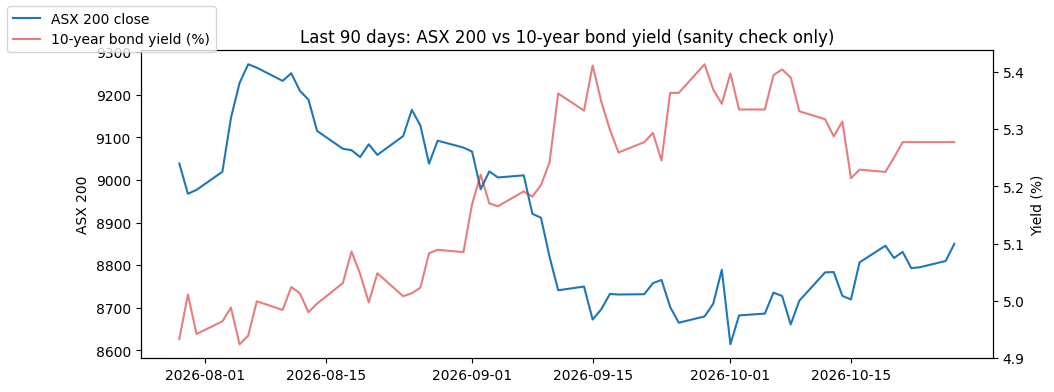

      source                      check status                                                                     detail
yahoo_asx200                   download   PASS                                                379 rows saved to raw layer
 rba_bond10y                   download   PASS          3401 rows parsed; 10 description rows above the data were skipped
yahoo_asx200                     schema   PASS                                                Date, Close, Volume present
 rba_bond10y                     schema   PASS                                                        FCMYGBAG10D present
 rba_bond10y                 date_parse   PASS                                             0 rows with an unreadable date
yahoo_asx200            duplicate_dates   PASS                                                          0 duplicate dates
yahoo_asx200          null_asx200_close   PASS                                                           0 missing values
yahoo_asx200  non_positi

In [13]:
import matplotlib.pyplot as plt

last90 = merged[merged["date"] >= merged["date"].max() - pd.Timedelta(days=90)]
fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.plot(last90["date"], last90["asx200_close"], label="ASX 200 close")
ax1.set_ylabel("ASX 200")
ax2 = ax1.twinx()
ax2.plot(last90["date"], last90["bond10y_yield"], color="tab:red", alpha=0.6, label="10-year bond yield (%)")
ax2.set_ylabel("Yield (%)")
ax1.set_title("Last 90 days: ASX 200 vs 10-year bond yield (sanity check only)")
fig.legend(loc="upper left")
plt.show()

print(pd.read_csv(DQ_LOG_PATH).query("run_id == @RUN_ID")[["source", "check", "status", "detail"]].to_string(index=False))

## Next steps by role
- **Pipeline lead:** scheduling plan, failure demo (e.g. set `ASX_TICKER = "^BADTICKER"` and show the retry + FAIL log), architecture diagram.
- **Curation lead:** metric definitions in `docs/metric_definitions.md` first, then build metrics in `transform/` from `data/clean/market_daily.csv`.
- **Dashboard lead:** 90-day charts and the RAG signal (ASX 200 14-day volatility vs its past-year percentiles) in `dashboard/`.
- **Everyone:** log any AI mistakes in `docs/ai_log.md`.